# Daily time-step run with runtime changes

The high-level `Lintul5Model.forward` runs a whole season in one call, with a
**fixed** configuration. This example instead drives the model through its
**low-level, step-wise API** — one explicit-Euler day at a time — so we can
intervene _during_ the simulation and watch the trajectory respond from that day
onward. There are two distinct things you can edit between steps:

| What you edit                    | Where it lives                                      | How to edit it                               |
| -------------------------------- | --------------------------------------------------- | -------------------------------------------- |
| **Parameters** (e.g. RUE, TSUM)  | `model.crop_params` / `soil_params` / `site_params` | assign a new tensor on the dataclass         |
| **State** (e.g. LAI, soil water) | the `ModelState` flowing through the loop           | build a new state with `dataclasses.replace` |

The three building blocks of the step-wise API are:

| Method                                         | Role                                            |
| ---------------------------------------------- | ----------------------------------------------- |
| `model.initialize(batch_size, ...)`            | build the bare-soil, pre-emergence `ModelState` |
| `model.compute_rates(state, weather_day, doy)` | one day of physics → a dict of `*_rate` tensors |
| `model.update_state(state, rates, dt=1.0)`     | forward-Euler step → `state_{t+1}`              |

The key fact that makes **parameter** edits work: every process module reads its
constants straight off `model.crop_params` (and `soil_params` / `site_params`)
**on each call**. So if we assign a new value to, say,
`model.crop_params.scale_factor_rue` between two `compute_rates` calls, the very
next day already uses it — no re-instantiation, no recompilation. **State** edits
are even more direct: the `ModelState` is just a dataclass passed into
`compute_rates`, so we replace a field on it before handing it to the next step.

This notebook covers both, over one Brandenburg winter-wheat location:

1. **Parameter edit** — a step change to the radiation-use-efficiency scale factor
   `scale_factor_rue` at anthesis, in **potential production** mode
   (`iopt = 1`, `irri = 1`).
2. **State edits** — a leaf-area **defoliation** event (drop `LAI`) and a
   **soil-moisture** shock (drop root-zone water `wa`), in **water-limited,
   rain-fed** mode (`iopt = 2`, `irri = 0`) so the soil-water change actually
   persists and feeds back through water stress (`TRANRF`).


## Import libraries


In [9]:
import dataclasses
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from torchcrop import (
    CropParameters,
    SoilParameters,
    SiteParameters,
    Lintul5Model,
    WeatherDriver,
)

plt.rcParams["font.family"] = "DeJavu Serif"
plt.rcParams["font.serif"] = "Times New Roman"

DATA_DIR = Path("../data", "brandenburg", "torchcrop")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32
print(f"Using device: {device}")

Using device: cpu


## Load a single location

The step-wise loop is identical for any batch size, so to keep the focus on the
_mechanics_ we run a **single** Brandenburg location (`B = 1`). The helpers below
read that location's daily weather, soil, and site tables and assemble the
batched `WeatherDriver` / `SoilParameters` / `SiteParameters` objects torchcrop
expects. The column → field maps and the `TempMean = (TempMin + TempMax) / 2`,
`Radiation: kJ → MJ`, `Date → day-of-year` conventions match the other example
notebooks so the numbers line up.


In [10]:
# CSV weather columns, in the exact order torchcrop expects them
# (DOY, davtmp, tmin, tmax, irrad, rain, vp, wind).
WEATHER_COLS = [
    "Date", "TempMean", "TempMin", "TempMax",
    "Radiation", "Precipitation", "VapPressure", "Windspeed",
]

# soil.csv column -> SoilParameters field name.
SOIL_MAP = {
    "SMDRY": "wcad", "SMW": "wcwp", "SMFC": "wcfc", "SMO": "wcst",
    "CRAIRC": "crairc", "SMI": "wci", "SMLOWI": "wci_lower",
    "RDMSO": "rdmso", "RUNFR": "runfr", "CFEV": "cfev", "KSUB": "ksub",
    "NMINS": "nmini", "PMINS": "pmini", "KMINS": "kmini",
    "RTNMINS": "rtnmins", "RTPMINS": "rtpmins", "RTKMINS": "rtkmins",
}

# site.csv column -> SiteParameters field name.
SITE_MAP = {"LATITUDE": "latitude", "ALTITUDE": "altitude",
            "IDPL": "idpl", "CO2": "co2"}


def load_location(location, data_dir=DATA_DIR, dtype=dtype):
    """Return (weather, soil_params, site_params) for one location as B=1."""
    # --- weather: [1, T, 8] ---
    df = pd.read_csv(data_dir / "weather" / f"{location}.csv", parse_dates=["Date"])
    df = df[WEATHER_COLS].copy()
    # SIMPLACE drives phenology with TMPA = (TMIN + TMAX) / 2, not the measured
    # mean; match it so the run reproduces the reference.
    df["TempMean"] = (df["TempMin"] + df["TempMax"]) / 2.0
    df["Radiation"] = df["Radiation"] / 1000.0       # kJ -> MJ m-2 d-1
    df["Date"] = df["Date"].dt.dayofyear              # date -> day-of-year
    weather = torch.as_tensor(df.values, dtype=dtype).unsqueeze(0)  # [1, T, 8]
    weather = WeatherDriver(weather)

    # --- soil / site: one [1] tensor per field ---
    srow = pd.read_csv(data_dir / "soil" / "soil.csv").set_index("location").loc[location]
    soil_params = SoilParameters(**{
        field: torch.tensor([float(srow[col])], dtype=dtype)
        for col, field in SOIL_MAP.items()
    })

    trow = pd.read_csv(data_dir / "site" / "site.csv").set_index("location").loc[location]
    site_params = SiteParameters(**{
        field: torch.tensor([float(trow[col])], dtype=dtype)
        for col, field in SITE_MAP.items()
    })
    return weather, soil_params, site_params


LOCATION = 0
weather, soil_params, site_params = load_location(LOCATION)
print(f"Location {LOCATION}: weather {tuple(weather.data.shape)} "
      f"(B, T, channels), {weather.n_days} days")

Location 0: weather (1, 731, 8) (B, T, channels), 731 days


## Build the model (potential production)

We configure the same two switches as the potential-production example:
`crop_params.iopt = 1` (nutrient stress off) and `soil_params.irri = 1`
(automatic irrigation, so `TRANRF` stays at `1`). Everything is moved onto the
target device up front; the step-wise loop never touches NumPy.


In [11]:
crop_params = CropParameters(crop_name="wheat")
crop_params.iopt = torch.tensor(1.0)     # potential mode: nutrient stress off
soil_params.irri = torch.tensor(1.0)     # automatic irrigation: water non-limiting

crop_params = crop_params.to(device=device)
soil_params = soil_params.to(device=device)
site_params = site_params.to(device=device)
weather = weather.to(device=device)

model = Lintul5Model(crop_params, soil_params, site_params).eval().to(device)

# The baseline RUE scale factor we will perturb later.
print("Default scale_factor_rue:", float(model.crop_params.scale_factor_rue))

Default scale_factor_rue: 1.0


## A reusable step-wise run

`run_stepwise` reproduces exactly what `SimulationEngine.run` does internally —
loop over the `T` weather days, build the per-day channel dict and `doy` tensor,
call `compute_rates`, then `update_state` — but adds **one hook**: an optional
`on_step(t, state, model)` callback invoked _before_ each day's rates are
computed. The callback can do either or both of:

- **edit a parameter** — mutate `model.crop_params` (or soil/site params) in
  place; the process modules re-read those tensors every call, so it takes effect
  immediately. Return `None`.
- **edit the state** — return a _new_ `ModelState` (built with
  `dataclasses.replace`, never an in-place write, to stay autograd-safe); the loop
  swaps it in for this day onward.

We record the per-day `ModelState` snapshots, the `scale_factor_rue` in force each
day, and the water-stress factor `TRANRF` from the rates dict, so we can plot both
the response and the perturbation that caused it.

`torch.no_grad()` keeps this a pure forward simulation; drop it (and make the
edited value an `nn.Parameter`) if you want gradients to flow through it.


In [12]:
@torch.no_grad()
def run_stepwise(model, weather, start_doy=1, on_step=None):
    """Drive the model day-by-day with an optional per-day edit hook.

    `on_step(t, state, model)` may mutate `model.*_params` in place and/or
    return a new `ModelState` to use from day `t` onward (or `None` for no
    state change).

    Returns a dict of stacked per-day trajectories:
        dvs, lai, biomass, wso, wa  -> [T+1] (leading initial-condition entry)
        rue_scale, tranrf           -> [T]   (value in force on each weather day)
    """
    B = weather.batch_size
    state = model.initialize(batch_size=B, dtype=weather.data.dtype,
                             device=weather.data.device)
    states = [state]
    rue_scale, tranrf = [], []
    for t in range(weather.n_days):
        if on_step is not None:
            edited = on_step(t, state, model)   # param edits (in place) and/or...
            if edited is not None:              # ...a replacement state for today
                state = edited
                states[-1] = state              # reflect the edit in the trajectory
        rue_scale.append(float(model.crop_params.scale_factor_rue))

        weather_day = weather.day(t)
        doy = torch.full_like(state.dvs, float(((start_doy - 1 + t) % 365) + 1))
        rates = model.compute_rates(state, weather_day, doy)
        tranrf.append(float(rates["tranrf"][0]))
        state = model.update_state(state, rates, dt=1.0)
        states.append(state)

    to_np = lambda xs: torch.stack(xs, dim=1)[0].cpu().numpy()  # noqa: E731
    return {
        "dvs": to_np([s.dvs for s in states]),
        "lai": to_np([s.lai for s in states]),
        "biomass": to_np([s.wlv + s.wst + s.wso for s in states]),
        "wso": to_np([s.wso for s in states]),
        "wa": to_np([s.wa for s in states]),
        "rue_scale": np.asarray(rue_scale),
        "tranrf": np.asarray(tranrf),
    }

# Part 1 — Parameter edit: drop RUE at anthesis

## Baseline run (parameters held constant)

First, a reference run with no edits — `scale_factor_rue` stays at its default
`1.0` for the whole season. This matches what `model(weather, start_doy=1)`
would give.


In [13]:
# Make sure we start from the default before each run.
model.crop_params.scale_factor_rue = torch.tensor(
    1.0, dtype=dtype, device=device
)

baseline = run_stepwise(model, weather, start_doy=1)
print(f"Baseline final yield (WSO): {baseline['wso'][-1]:.1f} g m-2")
print(f"Baseline peak LAI:          {baseline['lai'].max():.2f} m2 m-2")

Baseline final yield (WSO): 487.0 g m-2
Baseline peak LAI:          1.80 m2 m-2


## Runtime change: drop RUE at anthesis

Now the point of the exercise. We register an `on_step` callback that, **the
first day development stage `DVS` reaches `1.0` (anthesis)**, scales
`scale_factor_rue` down to `0.6` — a 40 % cut in radiation-use efficiency from
flowering onward. Because the decision is made on the _live_ `state.dvs`, the
edit is data-driven, not hard-wired to a calendar day; it would fire on a
different day for a different location or weather year.

The callback only fires once (guarded by a mutable flag) and prints the day it
triggers so the change is visible in the log.


In [14]:
def make_rue_dropper(threshold_dvs=1.0, new_scale=0.6):
    """Return an `on_step` hook that cuts RUE once DVS crosses `threshold_dvs`."""
    fired = {"done": False}

    def on_step(t, state, model):
        if not fired["done"] and float(state.dvs[0]) >= threshold_dvs:
            model.crop_params.scale_factor_rue = torch.tensor(
                new_scale, dtype=state.dvs.dtype, device=state.dvs.device
            )
            fired["done"] = True
            print(f"  day index {t}: DVS={float(state.dvs[0]):.2f} -> "
                  f"scale_factor_rue set to {new_scale}")
    return on_step


# Reset to default, then run with the data-driven edit.
model.crop_params.scale_factor_rue = torch.tensor(1.0, dtype=dtype, device=device)
perturbed = run_stepwise(model, weather, start_doy=1,
                         on_step=make_rue_dropper(threshold_dvs=1.0, new_scale=0.6))

print(f"\nPerturbed final yield (WSO): {perturbed['wso'][-1]:.1f} g m-2")
loss = 100.0 * (1.0 - perturbed['wso'][-1] / baseline['wso'][-1])
print(f"Yield change vs baseline:    -{loss:.1f}%")

  day index 476: DVS=1.00 -> scale_factor_rue set to 0.6

Perturbed final yield (WSO): 300.8 g m-2
Yield change vs baseline:    -38.2%


## Visualise the response

Four panels share a day-index x-axis (day `0` = 1 January; the flat early stretch
is the pre-emergence spin-up handled by the sowing latch):

1. **`scale_factor_rue`** actually in force each day — flat at `1.0` for the
   baseline, stepping down to `0.6` at anthesis for the perturbed run.
2. **LAI** — the perturbed canopy stops expanding and senesces sooner.
3. **Total above-ground biomass** (`WLV + WST + WSO`).
4. **Storage-organ weight `WSO`** — the model's yield variable; the gap at the
   right edge is the yield penalty printed above.

A dashed vertical line marks the day the edit fired.


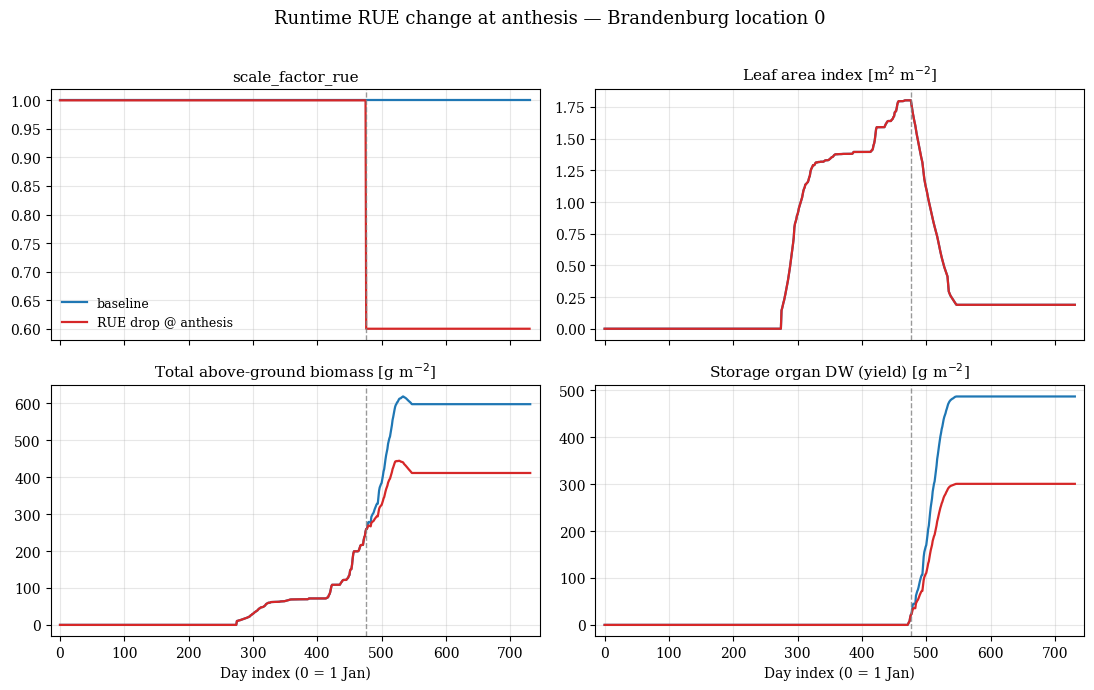

In [15]:
# Day the perturbation kicked in (first day the perturbed scale != 1.0).
changed = np.where(perturbed["rue_scale"] != 1.0)[0]
change_day = int(changed[0]) if len(changed) else None

days_state = np.arange(len(baseline["lai"]))     # T + 1
days_rate = np.arange(len(baseline["rue_scale"]))  # T

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
panels = [
    ("rue_scale", days_rate, "scale_factor_rue", "-"),
    ("lai", days_state, "Leaf area index [m$^2$ m$^{-2}$]", "m$^2$ m$^{-2}$"),
    ("biomass", days_state, "Total above-ground biomass [g m$^{-2}$]", ""),
    ("wso", days_state, "Storage organ DW (yield) [g m$^{-2}$]", ""),
]
for ax, (key, x, title, _unit) in zip(axes.ravel(), panels):
    ax.plot(x, baseline[key], color="#1f77b4", lw=1.6, label="baseline")
    ax.plot(x, perturbed[key], color="#d62728", lw=1.6, ls="-", label="RUE drop @ anthesis")
    if change_day is not None:
        ax.axvline(change_day, color="grey", ls="--", lw=1.0, alpha=0.8)
    ax.set_title(title, fontsize=11)
    ax.grid(alpha=0.3)
    ax.margins(x=0.02)

for ax in axes[-1]:
    ax.set_xlabel("Day index (0 = 1 Jan)")
axes[0, 0].legend(fontsize=9, frameon=False)
fig.suptitle(f"Runtime RUE change at anthesis — Brandenburg location {LOCATION}",
             fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

# Part 2 — State edits: LAI and soil moisture

`LAI` and root-zone soil water `wa` are **state** variables — they live on the
`ModelState`, not on the parameter dataclasses — so we edit them differently.
Inside `on_step` we return a _new_ state built with
[`dataclasses.replace`](https://docs.python.org/3/library/dataclasses.html#dataclasses.replace),
which copies the dataclass with the named fields swapped out. This respects the
project's **no-in-place-writes** rule (we never do `state.lai[...] = ...`), so the
same hook works unchanged inside an autograd-tracked run.

**Why a different production mode here.** In Part 1's potential mode the water
balance refills the root zone to field capacity every day and `TRANRF` is pinned
at `1`, so a one-off edit to `wa` would simply wash out and never affect growth.
To make the soil-moisture edit _meaningful_ we switch to **water-limited,
rain-fed** mode (`iopt = 2`, `irri = 0`): now `wa` is a genuine prognostic store,
and water stress `TRANRF = f(wa)` throttles assimilation. `LAI` already matters in
either mode (it sets light interception), but we keep both edits in the same
water-limited run for a single, consistent comparison.


In [16]:
# A fresh model for this location in water-limited, rain-fed mode.
weather_wl, soil_wl, site_wl = load_location(LOCATION)

crop_wl = CropParameters(crop_name="wheat")
crop_wl.iopt = torch.tensor(2.0)     # water-limited: water stress active
soil_wl.irri = torch.tensor(0.0)     # rain-fed: no automatic refill

crop_wl = crop_wl.to(device=device)
soil_wl = soil_wl.to(device=device)
site_wl = site_wl.to(device=device)
weather_wl = weather_wl.to(device=device)

model_wl = Lintul5Model(crop_wl, soil_wl, site_wl).eval().to(device)

# Reference run with no edits.
baseline_wl = run_stepwise(model_wl, weather_wl, start_doy=1)
print(f"Water-limited baseline yield: {baseline_wl['wso'][-1]:.1f} g m-2")

# Pick a data-driven event day: the first day the canopy is established
# (DVS >= 0.5), so both edits land during active growth.
event_day = int(np.argmax(baseline_wl["dvs"][:-1] >= 0.5))
print(f"Event day index: {event_day} (DVS={baseline_wl['dvs'][event_day]:.2f})")

Water-limited baseline yield: 456.2 g m-2
Event day index: 332 (DVS=0.50)


### Two state-edit hooks

- **Defoliation** — on a single day, halve the leaf area: replace `lai` with
  `lai * keep`. (A fuller "hail/grazing" model would scale green-leaf mass `wlv`
  too; we keep it to `lai` to isolate the light-interception pathway.)
- **Drought** — impose a dry spell: for every day in a window, knock the root-zone
  water down to a fraction of its current value (`wa * keep`). Because the water
  balance is now prognostic, this drags `TRANRF` down and suppresses growth until
  rains refill the profile.

Both are pure `dataclasses.replace` edits returned from `on_step`; neither touches
`model_wl`'s parameters, so the three runs below share one model with no resets.


In [17]:
def make_defoliation(day, keep=0.5):
    """`on_step` hook: halve LAI on a single `day`."""
    def on_step(t, state, model):
        if t == day:
            print(f"  day {t}: defoliation, LAI {float(state.lai[0]):.2f} -> "
                  f"{float(state.lai[0]) * keep:.2f}")
            return dataclasses.replace(state, lai=state.lai * keep)
        return None
    return on_step


def make_drought(day, duration=30, keep=0.3):
    """`on_step` hook: hold root-zone water at a fraction over a dry-spell window."""
    def on_step(t, state, model):
        if day <= t < day + duration:
            return dataclasses.replace(state, wa=state.wa * keep)
        return None
    return on_step


defoliation = run_stepwise(model_wl, weather_wl, start_doy=1,
                           on_step=make_defoliation(event_day, keep=0.5))
drought = run_stepwise(model_wl, weather_wl, start_doy=1,
                       on_step=make_drought(event_day, duration=30, keep=0.3))

for name, run in [("defoliation (LAI x0.5)", defoliation),
                  ("drought (wa x0.3, 30 d)", drought)]:
    dy = 100.0 * (1.0 - run['wso'][-1] / baseline_wl['wso'][-1])
    print(f"{name:26s}: yield {run['wso'][-1]:6.1f} g m-2  ({-dy:+.1f}%)")

  day 332: defoliation, LAI 1.32 -> 0.66
defoliation (LAI x0.5)    : yield  293.1 g m-2  (-35.8%)
drought (wa x0.3, 30 d)   : yield   46.1 g m-2  (-89.9%)


### Visualise the state edits

The same four-panel layout, now with three lines (baseline, defoliation,
drought). The grey band marks the 30-day drought window; the dashed line marks
the single defoliation day.

1. **LAI** — drops sharply on the defoliation day, then keeps developing from the
   lowered level.
2. **Root-zone water `wa`** — held down through the drought window, then recovers.
3. **Water stress `TRANRF`** — falls during the dry spell (`1` = unstressed);
   flat at the top for the others.
4. **Storage-organ weight `WSO`** — the resulting yield gap for each scenario.


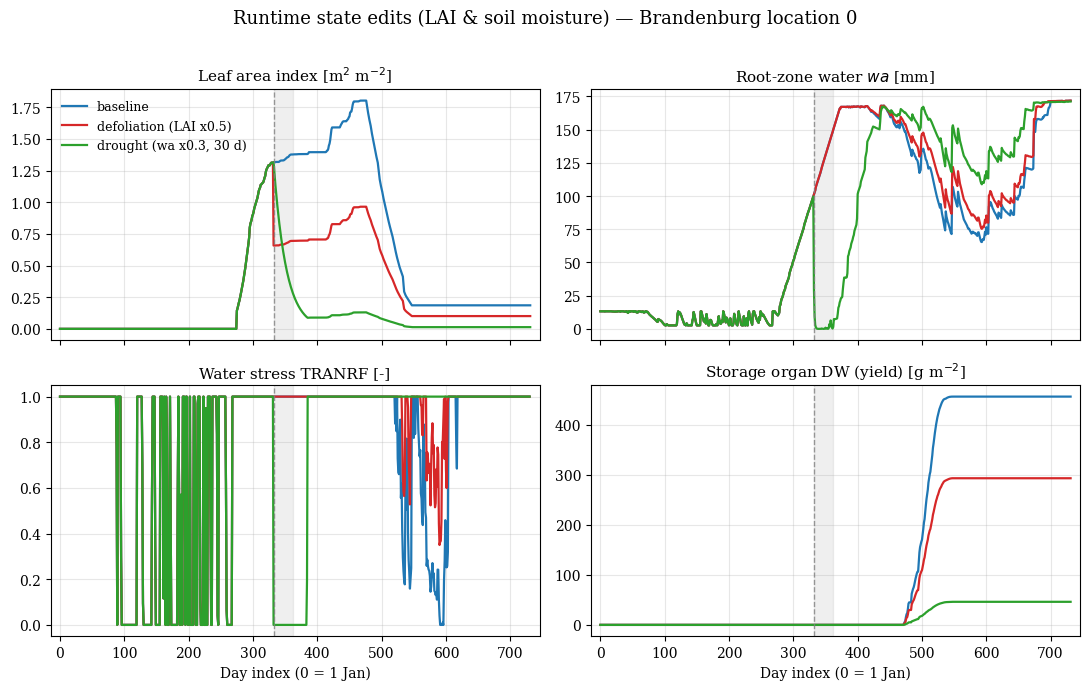

In [18]:
days_state = np.arange(len(baseline_wl["lai"]))     # T + 1
days_rate = np.arange(len(baseline_wl["tranrf"]))   # T

runs = [
    ("baseline", baseline_wl, "#1f77b4"),
    ("defoliation (LAI x0.5)", defoliation, "#d62728"),
    ("drought (wa x0.3, 30 d)", drought, "#2ca02c"),
]
panels = [
    ("lai", days_state, "Leaf area index [m$^2$ m$^{-2}$]"),
    ("wa", days_state, "Root-zone water $wa$ [mm]"),
    ("tranrf", days_rate, "Water stress TRANRF [-]"),
    ("wso", days_state, "Storage organ DW (yield) [g m$^{-2}$]"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, (key, x, title) in zip(axes.ravel(), panels):
    for label, run, color in runs:
        ax.plot(x, run[key], color=color, lw=1.6, label=label)
    ax.axvspan(event_day, event_day + 30, color="grey", alpha=0.12)
    ax.axvline(event_day, color="grey", ls="--", lw=1.0, alpha=0.8)
    ax.set_title(title, fontsize=11)
    ax.grid(alpha=0.3)
    ax.margins(x=0.02)

for ax in axes[-1]:
    ax.set_xlabel("Day index (0 = 1 Jan)")
axes[0, 0].legend(fontsize=9, frameon=False)
fig.suptitle(
    f"Runtime state edits (LAI & soil moisture) — Brandenburg location {LOCATION}",
    fontsize=13,
)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

## Takeaways

- The step-wise API (`initialize` → `compute_rates` → `update_state`) exposes the
  state **between** every Euler day, which is exactly where runtime edits belong.
- **Parameter edits**: mutate `model.crop_params.<name>` (or `soil_params` /
  `site_params`) in place — it takes effect on the **next** `compute_rates` call,
  because the process modules read those tensors fresh each step.
- **State edits**: return a new `ModelState` from the hook via
  `dataclasses.replace(state, lai=..., wa=...)`. No in-place writes, so the same
  edit is safe inside an autograd-tracked run.
- Edits can be **state-driven** (keyed on live `DVS` here) rather than tied to a
  calendar day, so the same logic adapts across locations and years.
- Match the **production mode** to the edit: a soil-water edit only persists in
  water-limited / rain-fed mode (`iopt = 2`, `irri = 0`); in potential mode the
  water balance refills it and `TRANRF` stays at `1`.
- For optimisation, drop `torch.no_grad()` and make the edited value an
  `nn.Parameter`: gradients then flow through the full day-by-day chain. For
  pre-planned daily inputs you don't need this loop at all — pass
  `irrigation [B, T]` / `fertilizer [B, T, 3]` straight to `model(...)`.


# Part 3 — Data Assimilation: Kalman Filter / 3D-Var for LAI

Instead of synthetic state edits we now assimilate **real** sparse LAI
observations (~10-day revisit from `fetch_LAI/lai_outputs/LAI_<loc>.csv`)
into the model's LAI state using a **scalar Kalman Filter** — equivalent to
a 3D-Var analysis at each observation window.

### Filter formulation

The observation operator is **H = 1** (we observe LAI directly), so the full
multi-variate KF collapses to three scalar equations per observation day:

| Step | Equation | Meaning |
|---|---|---|
| Forecast cov. | P_f = P_a + Q | uncertainty grows between scenes |
| Kalman gain | K = P_f / (P_f + R) | weight given to the observation |
| Analysis | x_a = x_f + K (y − x_f) | BLUE blend of forecast and obs |
| Analysis cov. | P_a = (1 − K) P_f | posterior uncertainty |

R = σ_obs² is the **observation error variance** (user-supplied `sigma_obs`).  
Q = σ_q² is the **process noise** added every day to model growing uncertainty
between satellite passes.

On days without an observation only P is propagated (P ← P + Q); the model
state is left unchanged and the next `compute_rates` call sees the model's
uncorrected forecast.

In [19]:
# ─── 3.1  Helper functions ────────────────────────────────────────────────


def load_lai_observations(lai_csv_path, sim_start_date, n_days):
    """
    Map sparse LAI observations from a CSV file onto simulation day indices.

    The CSV must have columns ``date`` (parseable date string) and
    ``lai_mean`` (float). Rows with a missing ``lai_mean`` are dropped —
    they represent cloud-contaminated or otherwise unusable scenes.

    Parameters
    ----------
    lai_csv_path   : str or Path  — path to the CSV
    sim_start_date : str          — calendar date of day index 0 ("YYYY-MM-DD")
    n_days         : int          — simulation length; dates outside [0, n_days)
                                    are silently discarded

    Returns
    -------
    dict[int, float]
        {day_index: lai_obs} for every valid observation within the window.
    """
    df = pd.read_csv(lai_csv_path, parse_dates=["date"])
    df = df.dropna(subset=["lai_mean"])

    start = pd.Timestamp(sim_start_date)
    obs = {}
    for _, row in df.iterrows():
        d = int((row["date"] - start).days)
        if 0 <= d < n_days:
            obs[d] = float(row["lai_mean"])
    return obs


def make_lai_kf_hook(obs_by_day, sigma_obs=0.5, sigma_b0=1.0, sigma_q=0.05):
    """
    Build a ``run_stepwise`` on_step hook implementing a scalar Kalman Filter
    (KF) / 3D-Var analysis for LAI.  Works with batch size B = 1.

    Formulation
    -----------
    Observation operator H = 1 (LAI observed directly).  At each day t:

      P_f  = P_a(t-1) + Q            # forecast error covariance
      K    = P_f / (P_f + R)         # Kalman gain  ∈ (0, 1)
      x_a  = x_f + K * (y - x_f)    # analysis — BLUE estimator
      P_a  = (1 - K) * P_f           # analysis error covariance

    where R = sigma_obs² and Q = sigma_q² (process noise per day).
    On days without an observation the state passes through unchanged and
    P is propagated as P ← P + Q (uncertainty grows between scenes).

    Parameters
    ----------
    obs_by_day : dict[int, float]
        Sparse observations keyed by simulation day index; from
        ``load_lai_observations``.
    sigma_obs  : float
        Observation error standard deviation [m² m⁻²].
        Sets R = sigma_obs².
    sigma_b0   : float
        Initial background error standard deviation.
        Sets P₀ = sigma_b0².
    sigma_q    : float
        Process noise standard deviation per day.
        Sets Q = sigma_q².

    Returns
    -------
    on_step : callable
        Hook for ``run_stepwise(on_step=...)``.  Called *before*
        ``compute_rates`` each day so the analysis LAI feeds into that
        day's light-interception and growth calculations.
    da_log : dict
        Mutable dict filled during the run.  Key = day index; value =
        dict with keys: lai_f, lai_obs (None if absent), lai_a, K, P_f, P_a.
    """
    R  = sigma_obs ** 2          # observation error variance
    Q  = sigma_q  ** 2           # process noise variance per day

    kf     = {"P": sigma_b0 ** 2}   # mutable KF state (background error var.)
    da_log = {}                       # diagnostic accumulator

    def on_step(t, state, model):
        # Forecast step: uncertainty grows every day by Q.
        P_f   = kf["P"] + Q
        lai_f = float(state.lai[0])    # model-propagated (forecast) LAI

        if t in obs_by_day:
            # ── Analysis: blend forecast with observation ──────────────────
            y     = obs_by_day[t]
            K     = P_f / (P_f + R)                   # Kalman gain
            lai_a = lai_f + K * (y - lai_f)           # analysis LAI
            lai_a = max(lai_a, 0.0)                   # enforce physical bound
            P_a   = (1.0 - K) * P_f                   # analysis error covariance

            kf["P"] = P_a
            da_log[t] = dict(
                lai_f=lai_f, lai_obs=y, lai_a=lai_a,
                K=K, P_f=P_f, P_a=P_a,
            )
            # Return a new ModelState with the corrected LAI.
            # `dataclasses.replace` avoids any in-place tensor write,
            # keeping this safe inside an autograd-tracked run.
            new_lai = torch.tensor(
                [lai_a], dtype=state.lai.dtype, device=state.lai.device
            )
            return dataclasses.replace(state, lai=new_lai)

        else:
            # ── No observation: propagate background error only ────────────
            kf["P"] = P_f
            da_log[t] = dict(
                lai_f=lai_f, lai_obs=None, lai_a=lai_f,
                K=0.0, P_f=P_f, P_a=P_f,
            )
            return None   # state unchanged

    return on_step, da_log

In [20]:
# ─── 3.2  Load observations & run the assimilation loop ──────────────────

LAI_OBS_DIR    = Path("fetch_LAI/lai_outputs")
SIM_START_DATE = "2020-01-01"   # calendar date of simulation day index 0

# ── Tunable parameters ─────────────────────────────────────────────────────
# Adjust these to reflect prior knowledge of observation and model quality.
SIGMA_OBS = 0.5    # observation error std dev [m² m⁻²]  →  R  = SIGMA_OBS²
SIGMA_B0  = 1.0    # initial background error std dev     →  P₀ = SIGMA_B0²
SIGMA_Q   = 0.05   # process noise std dev per day        →  Q  = SIGMA_Q²

# ── Fresh water-limited model for the DA run ───────────────────────────────
weather_da, soil_da, site_da = load_location(LOCATION)
crop_da = CropParameters(crop_name="wheat")
crop_da.iopt = torch.tensor(2.0)   # water-limited: water stress active
soil_da.irri = torch.tensor(0.0)   # rain-fed: no automatic irrigation

crop_da    = crop_da.to(device=device)
soil_da    = soil_da.to(device=device)
site_da    = site_da.to(device=device)
weather_da = weather_da.to(device=device)

model_da = Lintul5Model(crop_da, soil_da, site_da).eval().to(device)

# ── Load LAI observations ──────────────────────────────────────────────────
obs_by_day = load_lai_observations(
    LAI_OBS_DIR / f"LAI_{LOCATION}.csv",
    sim_start_date=SIM_START_DATE,
    n_days=weather_da.n_days,
)
print(f"Location {LOCATION}: {len(obs_by_day)} valid observations "
      f"(day {min(obs_by_day)} → day {max(obs_by_day)})")

# ── Open-loop run: no assimilation ────────────────────────────────────────
openloop_da = run_stepwise(model_da, weather_da, start_doy=1)

# ── Kalman Filter run ─────────────────────────────────────────────────────
# `da_log` is a shared mutable dict populated as the simulation runs;
# inspect it afterwards for per-day diagnostics.
kf_hook, da_log = make_lai_kf_hook(
    obs_by_day,
    sigma_obs=SIGMA_OBS,
    sigma_b0=SIGMA_B0,
    sigma_q=SIGMA_Q,
)
kf_run = run_stepwise(model_da, weather_da, start_doy=1, on_step=kf_hook)

n_analyses = sum(1 for v in da_log.values() if v["lai_obs"] is not None)
print(f"\n{'':>12}  peak LAI [m² m⁻²]  final WSO [g m⁻²]")
print(f"Open-loop      {openloop_da['lai'].max():>8.2f}           {openloop_da['wso'][-1]:>8.1f}")
print(f"KF-DA          {kf_run['lai'].max():>8.2f}           {kf_run['wso'][-1]:>8.1f}")
print(f"\n{n_analyses} KF analysis steps over {weather_da.n_days} simulation days")

Location 0: 73 valid observations (day 0 → day 730)

              peak LAI [m² m⁻²]  final WSO [g m⁻²]
Open-loop          1.80              456.2
KF-DA              3.32              685.9

73 KF analysis steps over 731 simulation days


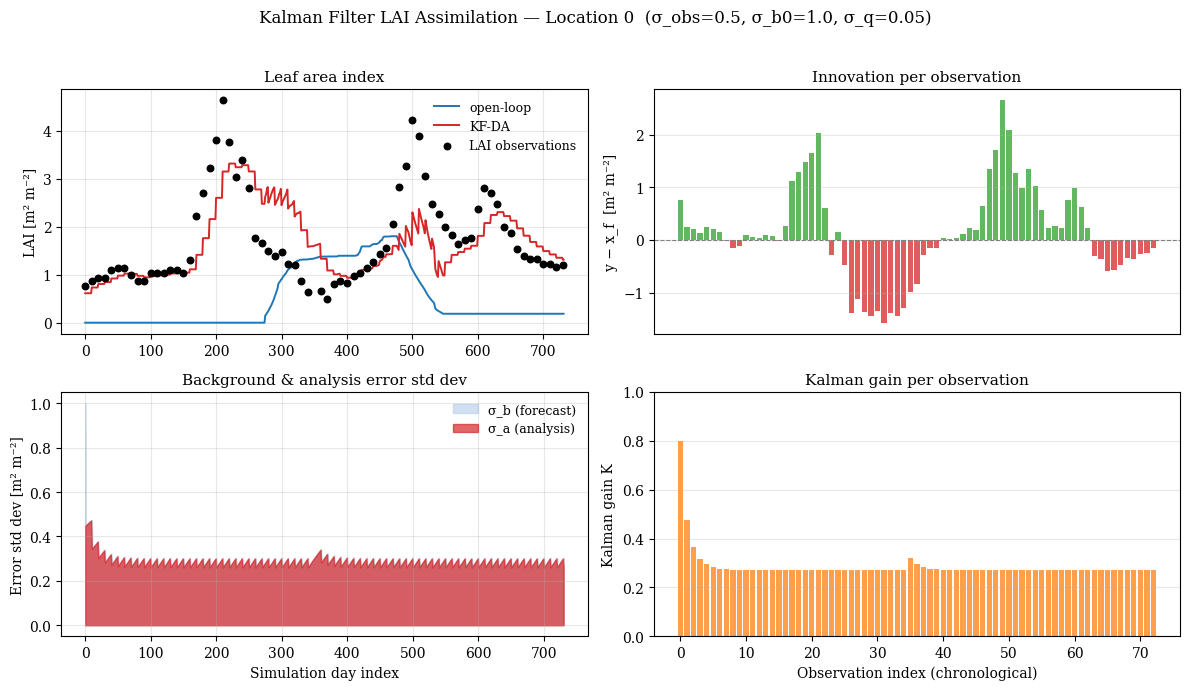

In [21]:
# ─── 3.3  Visualise the assimilation ──────────────────────────────────────

# Per-observation diagnostics (filter for days that had an observation).
obs_days  = sorted(d for d, v in da_log.items() if v["lai_obs"] is not None)
obs_vals  = [da_log[d]["lai_obs"] for d in obs_days]
inno_vals = [da_log[d]["lai_obs"] - da_log[d]["lai_f"] for d in obs_days]
K_vals    = [da_log[d]["K"]       for d in obs_days]

# Per-day error standard deviations (all T days).
all_days = sorted(da_log)
sigma_f  = np.sqrt([da_log[d]["P_f"] for d in all_days])
sigma_a  = np.sqrt([da_log[d]["P_a"] for d in all_days])

days_state = np.arange(len(openloop_da["lai"]))   # T+1

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
ax_lai, ax_inno = axes[0]
ax_P,   ax_K    = axes[1]

# ── LAI trajectory ─────────────────────────────────────────────────────────
ax_lai.plot(days_state, openloop_da["lai"], color="#1f77b4", lw=1.4, label="open-loop")
ax_lai.plot(days_state, kf_run["lai"],      color="#d62728", lw=1.4, label="KF-DA")
ax_lai.scatter(obs_days, obs_vals, s=22, color="k", zorder=5, label="LAI observations")
ax_lai.set_ylabel("LAI [m² m⁻²]")
ax_lai.set_title("Leaf area index", fontsize=11)
ax_lai.legend(fontsize=9, frameon=False)
ax_lai.grid(alpha=0.3)

# ── Background vs analysis error std dev over time ─────────────────────────
ax_P.fill_between(all_days, sigma_f, alpha=0.55, color="#aec7e8", label="σ_b (forecast)")
ax_P.fill_between(all_days, sigma_a, alpha=0.70, color="#d62728", label="σ_a (analysis)")
ax_P.set_ylabel("Error std dev [m² m⁻²]")
ax_P.set_xlabel("Simulation day index")
ax_P.set_title("Background & analysis error std dev", fontsize=11)
ax_P.legend(fontsize=9, frameon=False)
ax_P.grid(alpha=0.3)

# ── Innovation (y − x_f) at each observation ───────────────────────────────
bar_colors = ["#2ca02c" if v >= 0 else "#d62728" for v in inno_vals]
ax_inno.bar(range(len(obs_days)), inno_vals, color=bar_colors, alpha=0.75)
ax_inno.axhline(0, color="grey", lw=0.8, ls="--")
ax_inno.set_ylabel("y − x_f  [m² m⁻²]")
ax_inno.set_title("Innovation per observation", fontsize=11)
ax_inno.set_xticks([])
ax_inno.grid(axis="y", alpha=0.3)

# ── Kalman gain at each observation ────────────────────────────────────────
ax_K.bar(range(len(K_vals)), K_vals, color="#ff7f0e", alpha=0.75)
ax_K.set_ylim(0, 1)
ax_K.set_ylabel("Kalman gain K")
ax_K.set_xlabel("Observation index (chronological)")
ax_K.set_title("Kalman gain per observation", fontsize=11)
ax_K.grid(axis="y", alpha=0.3)

fig.suptitle(
    f"Kalman Filter LAI Assimilation — Location {LOCATION}  "
    f"(σ_obs={SIGMA_OBS}, σ_b0={SIGMA_B0}, σ_q={SIGMA_Q})",
    fontsize=12,
)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [27]:
from scipy.stats import pearsonr

# ─── 3.4  Evaluate open-loop model fit across all locations ────────────────
# Metric: Pearson r between model LAI and observations, restricted to
# observation days where the model overestimates by more than 10 %
# (model_lai > 1.1 × obs_lai).  This isolates shape similarity from
# absolute bias, and focuses only on the high-model-bias regime.

ALL_LOCS = list(range(18))
TOP_N    = 5

loc_stats = {}

for loc in ALL_LOCS:
    try:
        w, s, si = load_location(loc)
    except Exception as exc:
        print(f"  Loc {loc:2d}: skipped — {exc}")
        continue

    crop_l = CropParameters(crop_name="wheat")
    crop_l.iopt = torch.tensor(2.0)
    s.irri      = torch.tensor(0.0)

    model_l = Lintul5Model(
        crop_l.to(device=device), s.to(device=device), si.to(device=device)
    ).eval().to(device)
    run_l = run_stepwise(model_l, w.to(device=device), start_doy=1)

    obs = load_lai_observations(
        LAI_OBS_DIR / f"LAI_{loc}.csv",
        sim_start_date=SIM_START_DATE,
        n_days=w.n_days,
    )

    # Filter to days where the model overestimates by > 10 %.
    hi_pairs = [
        (run_l["lai"][d], y)
        for d, y in obs.items()
        if run_l["lai"][d] > 1.1 * y
    ]

    if len(hi_pairs) >= 2:
        m_vals, o_vals = zip(*hi_pairs)
        r, _ = pearsonr(m_vals, o_vals)   # shape correlation on hi-bias days
    else:
        r = np.nan   # too few qualifying days to compute correlation

    loc_stats[loc] = {"run": run_l, "obs": obs, "r": r, "n_hi": len(hi_pairs)}
    flag = f"r={r:+.3f}" if not np.isnan(r) else "r=N/A"
    print(f"  Loc {loc:2d}: {len(obs):2d} obs  "
          f"{len(hi_pairs):2d} days model>obs+10%  {flag}")

# Rank by r descending (r → 1 = best shape match); NaN sorts to worst.
ranked = sorted(
    loc_stats,
    key=lambda l: loc_stats[l]["r"] if not np.isnan(loc_stats[l]["r"]) else -np.inf,
    reverse=True,
)
best_locs  = set(ranked[:TOP_N])
worst_locs = set(ranked[-TOP_N:])

print(f"\nBest  {TOP_N} shape match (r → 1): locations {ranked[:TOP_N]}")
print(f"Worst {TOP_N} shape match (r → 0): locations {ranked[-TOP_N:]}")

  Loc  0: 73 obs  13 days model>obs+10%  r=+0.923
  Loc  1: 74 obs  17 days model>obs+10%  r=+0.333
  Loc  2: 73 obs  19 days model>obs+10%  r=+0.652
  Loc  3: 71 obs  14 days model>obs+10%  r=+0.477
  Loc  4: 74 obs  17 days model>obs+10%  r=+0.833
  Loc  5: 74 obs  23 days model>obs+10%  r=+0.509


/tmp/ipykernel_685457/210963845.py:45: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, _ = pearsonr(m_vals, o_vals)   # shape correlation on hi-bias days


  Loc  6: 74 obs   2 days model>obs+10%  r=N/A
  Loc  7: 74 obs  12 days model>obs+10%  r=+0.426
  Loc  8: 74 obs  18 days model>obs+10%  r=+0.314
  Loc  9: 74 obs  18 days model>obs+10%  r=+0.562
  Loc 10: 72 obs   0 days model>obs+10%  r=N/A
  Loc 11: 74 obs  19 days model>obs+10%  r=+0.517
  Loc 12: 74 obs  16 days model>obs+10%  r=+0.667
  Loc 13: 74 obs  15 days model>obs+10%  r=+0.696
  Loc 14: 74 obs  18 days model>obs+10%  r=+0.406
  Loc 15: 74 obs  22 days model>obs+10%  r=-0.401
  Loc 16: 74 obs  16 days model>obs+10%  r=+0.760
  Loc 17: 74 obs   2 days model>obs+10%  r=+1.000

Best  5 shape match (r → 1): locations [17, 0, 4, 16, 13]
Worst 5 shape match (r → 0): locations [1, 8, 15, 6, 10]


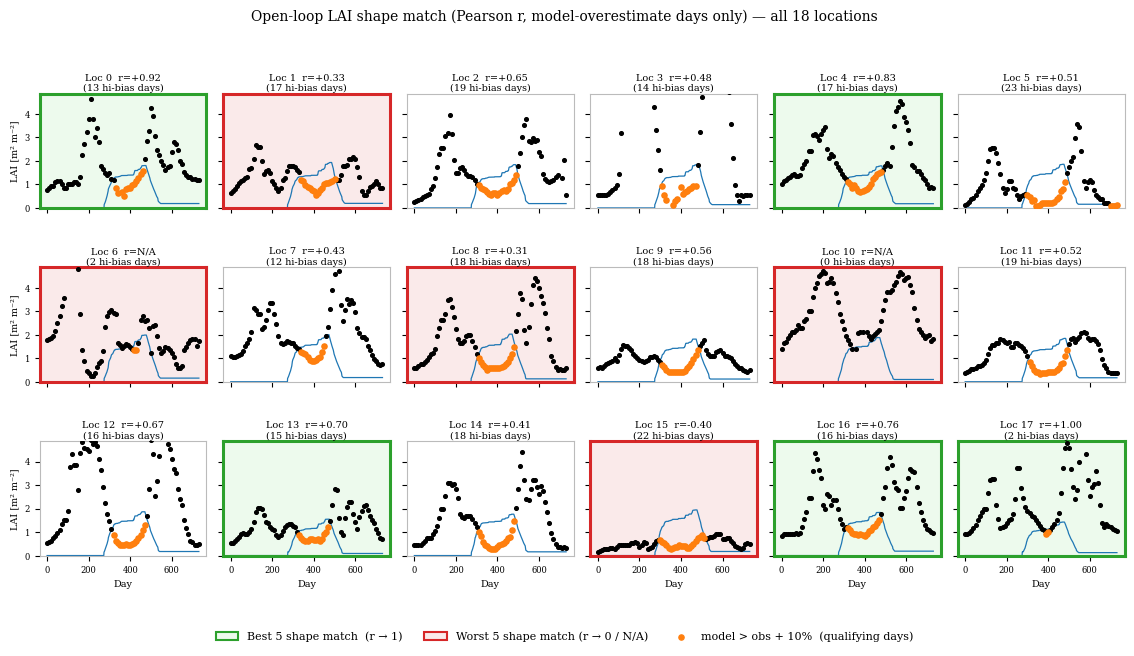

In [29]:
from matplotlib.patches import Patch

# ─── 3.5  Grid plot: all locations, coloured by shape-match quality ────────

n_locs = len(loc_stats)
ncols  = 6
nrows  = (n_locs + ncols - 1) // ncols

days_s = np.arange(weather_da.n_days + 1)

fig, axes = plt.subplots(
    nrows, ncols, figsize=(14, 6),
    sharex=True, sharey=True,
    gridspec_kw={"hspace": 0.52, "wspace": 0.10},
)
axes = axes.ravel()

for i, loc in enumerate(sorted(loc_stats)):
    ax    = axes[i]
    stats = loc_stats[loc]
    r     = stats["r"]
    n_hi  = stats["n_hi"]

    if loc in best_locs:
        face_col, spine_col, border_lw = "#edfaed", "#2ca02c", 2.2
    elif loc in worst_locs:
        face_col, spine_col, border_lw = "#faeaea", "#d62728", 2.2
    else:
        face_col, spine_col, border_lw = "white", "#bbbbbb", 0.8

    ax.set_facecolor(face_col)
    for sp in ax.spines.values():
        sp.set_edgecolor(spine_col)
        sp.set_linewidth(border_lw)

    ax.plot(days_s, stats["run"]["lai"], color="#1f77b4", lw=0.9)

    obs = stats["obs"]
    if obs:
        od = sorted(obs)
        ax.scatter(od, [obs[d] for d in od], s=7, color="k", zorder=5)

    # Mark the qualifying (model > obs+10%) observation days in orange.
    hi_days = [d for d, y in obs.items() if stats["run"]["lai"][d] > 1.1 * y]
    if hi_days:
        ax.scatter(hi_days, [obs[d] for d in hi_days],
                   s=14, color="#ff7f0e", zorder=6)

    r_str = f"{r:+.2f}" if not np.isnan(r) else "N/A"
    ax.set_title(f"Loc {loc}  r={r_str}\n({n_hi} hi-bias days)", fontsize=7, pad=2)
    ax.set_ylim(bottom=0)
    ax.tick_params(labelsize=6)

for ax in axes[n_locs:]:
    ax.set_visible(False)

for j in range(ncols):
    axes[min((nrows - 1) * ncols + j, n_locs - 1)].set_xlabel("Day", fontsize=7)
for r_idx in range(nrows):
    axes[r_idx * ncols].set_ylabel("LAI [m² m⁻²]", fontsize=7)

fig.legend(
    handles=[
        Patch(facecolor="#edfaed", edgecolor="#2ca02c", lw=1.5,
              label=f"Best {TOP_N} shape match  (r → 1)"),
        Patch(facecolor="#faeaea", edgecolor="#d62728", lw=1.5,
              label=f"Worst {TOP_N} shape match (r → 0 / N/A)"),
        plt.scatter([], [], s=14, color="#ff7f0e",
                    label="model > obs + 10%  (qualifying days)"),
    ],
    loc="lower center", ncol=3, fontsize=8, frameon=False,
    bbox_to_anchor=(0.5, -0.05),
)
fig.suptitle(
    f"Open-loop LAI shape match (Pearson r, model-overestimate days only) — "
    f"all {n_locs} locations",
    fontsize=10, y=1.02,
)
plt.show()